# Apprentice network and the human-like solver

An apprentice network learns which moves are good from the solver's own experience, by expert iteration (`rl.expert_iteration`). Round 1 learns from plain AND-OR's solved attempts; each later round from the human-like solver the network has become. From each solved attempt it learns the moves played (loops cut out: a return to an earlier board rewinds to it) and, at every subgoal of every plan that worked, which option resolved it.

The **human-like solver** then arbitrates between intuition (the network's move) and deliberation (AND-OR's subgoal-by-subgoal reasoning, ordered by the network, with lapses `GAMMA`).

Training on many *different* puzzles is what makes the network transfer (`scripts/learnability.py`).

In [1]:
import sys
sys.path.append("../scripts")
import os
import random
import statistics

import matplotlib.pyplot as plt
import torch
from tqdm import tqdm

import and_or as ao
import rl

## Parameters

`N_TRAIN_PER_BIN = 200` gives 1,000 training puzzles. Each of the `EXIT_ROUNDS` rounds makes `ATTEMPTS_PER_PUZZLE` attempts per training and validation puzzle, then trains.

`HEURISTIC_TEMPERATURE` adds noise to the network's ordering, so options are tried in an order sampled by its preference rather than always the same one (see `rl.PolicyAgent`). At 0 the same board always gets the same choice and the solver repeats plans that undo each other; in a test at gamma 0.07, 1.0 raised the solve rate on 13-20-move puzzles by about 20 points over 0. It also applies while the human-like solver makes attempts in expert-iteration rounds 2+.

`ARBITRATION_THRESHOLDS` and `MEMORY` set the solver (see "Solving held-out puzzles" below), and `INTUITION_TEMPERATURE` the noise in its intuition: it samples its move from softmax(logits / temperature) - at 1, in proportion to the network's own move probabilities, matching deliberation's `HEURISTIC_TEMPERATURE`; at 0 it always plays its top move. `INTUITION_TEMPERATURES` are the values the temperature sweep tries. Solvers are compared on the `N_FOCUS_PUZZLES` test puzzles at `FOCUS_DISTANCES` moves, where they differ most - both in the threshold sweep and along the learning trajectory.

`CHECKPOINT_DIR` gets the network before training and after every training epoch, for the learning trajectory at the end; `TRAJECTORY_*` set which solvers it tracks and how many checkpoints it evaluates.

In [2]:
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
SEED = 0
BINS = [(1, 8), (9, 12), (13, 16), (17, 20), (21, 30)]  # distance-to-goal bins, sampled evenly
N_TRAIN_PER_BIN = 200
N_VAL_PER_BIN = 20  # validation puzzles: pick the best epoch
N_TEST_PER_BIN = 20  # held-out puzzles: never trained or selected on (topped up to N_FOCUS_PUZZLES at FOCUS_DISTANCES)
HEURISTIC_TEMPERATURE = 1.0

# expert iteration
EXIT_ROUNDS = 3
ATTEMPTS_PER_PUZZLE = 4
ATTEMPT_GAMMA = 0.07  # lapse probability while making training attempts
CHECKPOINT_DIR = "../models/checkpoints"  # the network after every epoch (see "Learning trajectory")

# evaluation
STATES_PER_PUZZLE = 50  # boards per test puzzle scored against exact search labels
SUBGOALS_PER_PUZZLE = 200  # subgoals per test puzzle scored against the oracle
FOCUS_DISTANCES = (17, 20)  # solvers are compared on test puzzles of this optimal length, where they differ most
N_FOCUS_PUZZLES = 100  # test puzzles at FOCUS_DISTANCES, shared by the threshold sweep and the learning trajectory
GAMMAS = [0.07, 0.2]  # AND-OR lapse probabilities to compare
ARBITRATION_THRESHOLDS = [0.0, 0.5, 0.8, 1.01]  # intuition's confidence bar; 0 = intuition only, > 1 = deliberation only
INTUITION_TEMPERATURE = 1.0  # intuition's sampling temperature everywhere but the temperature sweep; 0 = always its top move
INTUITION_TEMPERATURES = [0.0, 0.25, 0.5, 1.0, 2.0, 4.0, 8.0]  # the temperature sweep's values, for intuition only
MEMORY = 10  # recent boards the solver remembers; a move back to one of them triggers deliberation
N_RUNS = 3  # solve attempts per puzzle and solver
MAX_STEPS = 200

# learning trajectory
TRAJECTORY_THRESHOLDS = [0.0, 1.01]  # solvers to track: intuition only, deliberation only
TRAJECTORY_EVERY = 1  # evaluate every k-th checkpoint (always including the kept ones and the last)

## Loading data

Test, validation and training puzzles are disjoint samples from `rush_nw.txt`, evenly spread over the distance bins. The test set is then topped up to `N_FOCUS_PUZZLES` puzzles at `FOCUS_DISTANCES` moves (`focus`), drawn after training and validation so those stay the same whatever the test set holds. All test puzzles get exact search labels - a yardstick for evaluation only; the network never learns from them.

In [3]:
pool = rl.load_puzzle_pool("../data/rush_nw.txt")
test = rl.sample_by_distance(pool, BINS, N_TEST_PER_BIN, seed=SEED)
val = rl.sample_by_distance(pool, BINS, N_VAL_PER_BIN, seed=SEED + 1, exclude=[s for _, s in test])
train = rl.sample_by_distance(pool, BINS, N_TRAIN_PER_BIN, seed=SEED + 2,
                              exclude=[s for _, s in test + val])
lo, hi = FOCUS_DISTANCES
n_extra = N_FOCUS_PUZZLES - sum(lo <= d <= hi for d, _ in test)
test += rl.sample_by_distance(pool, [FOCUS_DISTANCES], max(n_extra, 0), seed=SEED + 3,
                              exclude=[s for _, s in test + val + train])
focus = [(d, s) for d, s in test if lo <= d <= hi]
print(f"{len(train)} training, {len(val)} validation, {len(test)} test puzzles "
      f"({len(focus)} of them at {lo}-{hi} moves)")

test_labels = rl.label_puzzles([s for _, s in test], STATES_PER_PUZZLE, seed=SEED + 2)
test_subgoals = rl.label_subgoals([s for _, s in test], SUBGOALS_PER_PUZZLE, seed=SEED + 2)

1000 training, 100 validation, 180 test puzzles (100 of them at 17-20 moves)


labelling subgoals: 100%|██████████| 180/180 [01:01<00:00,  2.93it/s]


## Training the apprentice

Three heads share one network (see `rl.PolicyNetwork`): which legal move to play now; for every car and destination, how soon it should get there - which, trained on subgoal choices too, is what orders AND-OR's options; and the distance to the goal.

In [4]:
# random.seed(SEED)
# torch.manual_seed(SEED)
# agent = rl.PolicyAgent(device=DEVICE, temperature=HEURISTIC_TEMPERATURE)

# rounds = rl.expert_iteration(agent, [s for _, s in train], [s for _, s in val], rounds=EXIT_ROUNDS,
#                              n_attempts=ATTEMPTS_PER_PUZZLE, gamma=ATTEMPT_GAMMA, seed=SEED,
#                              checkpoint_dir=CHECKPOINT_DIR)
# for r in rounds:
#     print(f"round {r['round']}: {r['solved']}/{r['attempts']} training attempts solved, "
#           f"{r['boards']} boards and {r['subgoals']} subgoals learned from; validation agreement with "
#           f"the round's own attempts: moves {r['agreement']:.0%}, subgoal options {r['subgoal_agreement']:.0%} "
#           f"(epoch {r['best_epoch']}, kept)")

In [5]:
# os.makedirs("../models", exist_ok=True)
# agent.save("../models/policy_agent_attempts.pt")
# To reuse a trained agent instead of retraining:
agent = rl.PolicyAgent.load("../models/policy_agent_attempts.pt", device=DEVICE)
agent.temperature = HEURISTIC_TEMPERATURE

## Held-out agreement

Against exact search labels on the test puzzles, by distance bin:

- **move**: how often the network's top legal move is optimal (vs. a random legal move);
- **ordering**: at the subgoals an oracle-ordered AND-OR search visits, how often the network's top option is one an optimal solution prefers (vs. a random option) - the judgment the human-like solver uses;
- **distance error**: how far off its distance-to-goal estimate is.

In [6]:
for lo_, hi_ in BINS:
    in_bin = [i for i, (d, _) in enumerate(test) if lo_ <= d <= hi_]
    boards = [e for i in in_bin for e in test_labels[i]]
    subgoals = [g for i in in_bin for g in test_subgoals[i]]
    m, o = rl.evaluate_agreement(agent, boards), rl.evaluate_subgoals(agent, subgoals)
    print(f"distance {lo_:>2}-{hi_:<2} ({len(in_bin)} puzzles): move {m['agreement']:.0%} (random {m['chance']:.0%}), "
          f"ordering {o['agreement']:.0%} (random {o['chance']:.0%}), distance error {m['distance_error']:.1f} moves")

distance  1-8  (20 puzzles): move 92% (random 23%), ordering 95% (random 61%), distance error 1.9 moves
distance  9-12 (20 puzzles): move 93% (random 26%), ordering 87% (random 60%), distance error 3.2 moves
distance 13-16 (20 puzzles): move 83% (random 26%), ordering 83% (random 57%), distance error 5.0 moves
distance 17-20 (100 puzzles): move 81% (random 26%), ordering 77% (random 53%), distance error 6.3 moves
distance 21-30 (20 puzzles): move 77% (random 26%), ordering 66% (random 50%), distance error 7.0 moves


## Solving held-out puzzles

The human-like solver arbitrates every turn between two modes (`rl.solve_arbitrated`):

- **intuition** - play a move sampled from the network's softmax at `INTUITION_TEMPERATURE` (at 0, always its top legal move), when the top move's probability is at least the threshold and the move doesn't return to one of the last `MEMORY` boards;
- **deliberation** - otherwise, one AND-OR pass ordered by the network (lapse probability `gamma`), whose moves are played. Going in circles counts as low confidence: a move back to a recent board makes the solver stop and think.

Threshold 0 is intuition only (apart from revisits); above 1 it is deliberation only. Plain AND-OR (random ordering, random lapse moves) is the untrained reference.

All solvers attempt the same `N_FOCUS_PUZZLES` test puzzles at `FOCUS_DISTANCES` moves (`focus`), `N_RUNS` times each. Error bars are standard errors across puzzles: a puzzle's attempts are averaged first, since attempts on the same puzzle aren't independent. Moves / optimal is averaged over puzzles with at least one solved attempt; the share of moves by intuition counts moves, so one deliberation that plays a long plan weighs as much as many intuitive moves.

In [7]:
def mean_se(values):
    """(mean, standard error) of the non-nan values."""
    values = [v for v in values if v == v]
    if not values:
        return float("nan"), float("nan")
    se = statistics.stdev(values) / len(values) ** 0.5 if len(values) > 1 else float("nan")
    return statistics.mean(values), se


def summarize(runs):
    """{metric: (mean, standard error across puzzles)} for attempt dicts that come puzzle by puzzle,
    N_RUNS each: solve rate, moves / optimal over solved attempts, share of moves by intuition."""
    groups = [runs[i:i + N_RUNS] for i in range(0, len(runs), N_RUNS)]
    solve, ratio, share = [], [], []
    for g in groups:
        solved = [r for r in g if r["solved"]]
        played = sum(r.get("intuitive", 0) + r.get("deliberate", 0) for r in g)
        solve.append(len(solved) / len(g))
        ratio.append(statistics.mean(r["moves"] / r["distance"] for r in solved) if solved else float("nan"))
        share.append(sum(r.get("intuitive", 0) for r in g) / played if played else float("nan"))
    return {"solve rate": mean_se(solve), "moves / optimal": mean_se(ratio), "intuition share": mean_se(share)}


def plain_runs(puzzles, gamma):
    """Plain AND-OR attempts, puzzle by puzzle, N_RUNS each."""
    random.seed(SEED)
    runs = []
    for d, state in tqdm(puzzles, desc=f"plain AND-OR, gamma={gamma}", leave=False):
        for _ in range(N_RUNS):
            moves = rl.solve_and_or(state, MAX_STEPS, gamma=gamma)
            runs.append({"solved": moves is not None, "moves": len(moves) if moves is not None else None,
                         "distance": d})
    return runs


def solver_name(threshold):
    if threshold <= 0:
        return "intuition only"
    if threshold > 1:
        return "deliberation only"
    return f"threshold {threshold}"


SOLVERS = ["plain AND-OR"] + [solver_name(t) for t in ARBITRATION_THRESHOLDS]
COLORS = {name: f"C{i}" for i, name in enumerate(SOLVERS)}  # one colour per solver in every plot
METRICS = [("solve rate", "Solve rate"), ("moves / optimal", "Moves / optimal (solved attempts)"),
           ("intuition share", "Share of moves by intuition")]


_arbitrated = {}  # (threshold, gamma, temperature) -> runs; re-run this cell after changing `agent` or `focus`


def arbitrated_runs(threshold, gamma, temperature=None):
    """rl.evaluate_arbitrated attempts on `focus`, puzzle by puzzle, N_RUNS each, with intuition at `temperature`
    (None = INTUITION_TEMPERATURE). Cached, so the temperature and threshold sweeps share runs. Deliberation only
    (threshold > 1) never consults intuition, so its temperature is ignored."""
    if temperature is None:
        temperature = INTUITION_TEMPERATURE
    if threshold > 1:
        temperature = 0.0
    key = (threshold, gamma, temperature)
    if key not in _arbitrated:
        _arbitrated[key] = rl.evaluate_arbitrated(agent, focus, N_RUNS, gamma, threshold, MEMORY, MAX_STEPS,
                                                  seed=SEED, temperature=temperature)
    return _arbitrated[key]


### Intuition temperature

Deliberation is noisy - it lapses (`gamma`) and samples the order it tries options in (`HEURISTIC_TEMPERATURE`) - while intuition at temperature 0 would always play the same move on the same board. Here the intuition-only solver samples its move from softmax(logits / T) for each T in `INTUITION_TEMPERATURES` (the rest of the notebook uses `INTUITION_TEMPERATURE`); as T grows its choice approaches a uniformly random legal move. Its confidence is still the top move's probability, so the temperature changes which move intuition plays, not when it is trusted.

Deliberation only never consults intuition, so it is run once per gamma and drawn as a reference (dashed, standard error shaded).

In [8]:
INTUITION_ONLY, DELIBERATION_ONLY = 0.0, 1.01  # thresholds
conditions = [(gamma, INTUITION_ONLY, temperature) for gamma in GAMMAS for temperature in INTUITION_TEMPERATURES]
conditions += [(gamma, DELIBERATION_ONLY, 0.0) for gamma in GAMMAS]  # the reference; doesn't use intuition
temperature_results = {}  # (solver, gamma, temperature) -> summarize(...)
for gamma, threshold, temperature in tqdm(conditions, desc="temperature sweep"):
    temperature_results[(solver_name(threshold), gamma, temperature)] = summarize(
        arbitrated_runs(threshold, gamma, temperature))

lo, hi = FOCUS_DISTANCES
print(f"{len(focus)} puzzles of {lo}-{hi} moves, {N_RUNS} attempts each; mean ± standard error across puzzles")
for (solver, gamma, temperature), r in temperature_results.items():
    parts = [f"{key} {m:.2f} ± {se:.2f}" for key, (m, se) in r.items() if m == m]
    print(f"  gamma={gamma:<5} T={temperature:<5} {solver:<18} " + ", ".join(parts))

temperature sweep: 100%|██████████| 16/16 [03:07<00:00, 11.73s/it]

100 puzzles of 17-20 moves, 3 attempts each; mean ± standard error across puzzles
  gamma=0.07  T=0.0   intuition only     solve rate 0.69 ± 0.04, moves / optimal 3.08 ± 0.24, intuition share 0.44 ± 0.02
  gamma=0.07  T=0.25  intuition only     solve rate 0.73 ± 0.04, moves / optimal 3.25 ± 0.23, intuition share 0.47 ± 0.02
  gamma=0.07  T=0.5   intuition only     solve rate 0.73 ± 0.04, moves / optimal 3.46 ± 0.25, intuition share 0.51 ± 0.02
  gamma=0.07  T=1.0   intuition only     solve rate 0.76 ± 0.04, moves / optimal 3.46 ± 0.21, intuition share 0.56 ± 0.02
  gamma=0.07  T=2.0   intuition only     solve rate 0.75 ± 0.04, moves / optimal 4.10 ± 0.21, intuition share 0.60 ± 0.01
  gamma=0.07  T=4.0   intuition only     solve rate 0.70 ± 0.04, moves / optimal 5.09 ± 0.23, intuition share 0.61 ± 0.01
  gamma=0.07  T=8.0   intuition only     solve rate 0.66 ± 0.04, moves / optimal 5.64 ± 0.26, intuition share 0.61 ± 0.01
  gamma=0.2   T=0.0   intuition only     solve rate 0.67 ± 0.04,

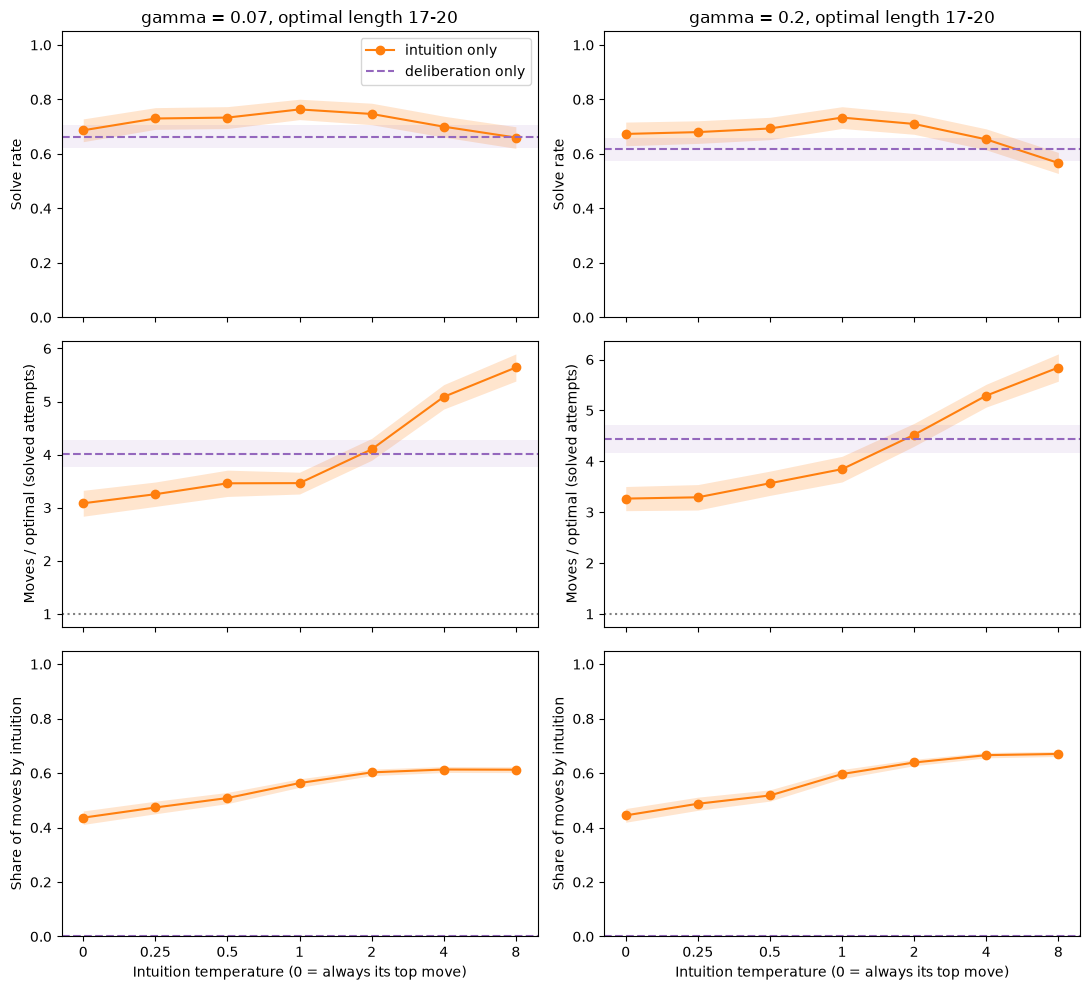

In [9]:
xs = range(len(INTUITION_TEMPERATURES))  # evenly spaced: the temperatures roughly double
intuition, reference = solver_name(INTUITION_ONLY), solver_name(DELIBERATION_ONLY)

fig, axes = plt.subplots(len(METRICS), len(GAMMAS), figsize=(5.5 * len(GAMMAS), 10), sharex=True, squeeze=False)
for col, gamma in enumerate(GAMMAS):
    for row, (key, ylabel) in enumerate(METRICS):
        ax = axes[row][col]
        stats = [temperature_results[(intuition, gamma, t)][key] for t in INTUITION_TEMPERATURES]
        ms = [s[0] for s in stats]
        ses = [s[1] if s[1] == s[1] else 0.0 for s in stats]
        ax.plot(xs, ms, marker="o", color=COLORS[intuition], label=intuition)
        ax.fill_between(xs, [m - e for m, e in zip(ms, ses)], [m + e for m, e in zip(ms, ses)],
                        color=COLORS[intuition], alpha=0.2, linewidth=0)
        m, se = temperature_results[(reference, gamma, 0.0)][key]
        ax.axhline(m, color=COLORS[reference], linestyle="--", label=reference)
        if se == se:
            ax.axhspan(m - se, m + se, color=COLORS[reference], alpha=0.1, linewidth=0)
        ax.set_ylabel(ylabel)
        if key == "moves / optimal":
            ax.axhline(1.0, color="gray", linestyle=":")
        else:
            ax.set_ylim(0, 1.05)
    axes[0][col].set_title(f"gamma = {gamma}, optimal length {lo}-{hi}")
    axes[-1][col].set_xticks(xs, [f"{t:g}" for t in INTUITION_TEMPERATURES])
    axes[-1][col].set_xlabel("Intuition temperature (0 = always its top move)")
axes[0][0].legend()
plt.tight_layout()
os.makedirs("../visualization", exist_ok=True)
plt.savefig("../visualization/intuition_temperature.png")
plt.show()

### Arbitration threshold

Every solver side by side with intuition at `INTUITION_TEMPERATURE`, against plain AND-OR.

In [ ]:
results = {}  # (solver, gamma) -> summarize(...), intuition at INTUITION_TEMPERATURE
for gamma in GAMMAS:
    results[("plain AND-OR", gamma)] = summarize(plain_runs(focus, gamma))
    for threshold in ARBITRATION_THRESHOLDS:
        results[(solver_name(threshold), gamma)] = summarize(arbitrated_runs(threshold, gamma))

lo, hi = FOCUS_DISTANCES
print(f"{len(focus)} puzzles of {lo}-{hi} moves, {N_RUNS} attempts each; mean ± standard error across puzzles")
for (solver, gamma), r in results.items():
    parts = [f"{key} {m:.2f} ± {se:.2f}" for key, (m, se) in r.items() if m == m]
    print(f"  gamma={gamma:<5} {solver:<18} " + ", ".join(parts))

In [ ]:
fig, axes = plt.subplots(len(METRICS), len(GAMMAS), figsize=(5.5 * len(GAMMAS), 10), sharex=True, squeeze=False)
for col, gamma in enumerate(GAMMAS):
    for row, (key, ylabel) in enumerate(METRICS):
        ax = axes[row][col]
        for x, solver in enumerate(SOLVERS):
            m, se = results[(solver, gamma)][key]
            if m == m:
                ax.errorbar(x, m, yerr=se, fmt="o", capsize=4, color=COLORS[solver])
        ax.set_ylabel(ylabel)
        if key == "moves / optimal":
            ax.axhline(1.0, color="gray", linestyle="--")
        else:
            ax.set_ylim(0, 1.05)
    axes[0][col].set_title(f"gamma = {gamma}, optimal length {lo}-{hi}")
    axes[-1][col].set_xticks(range(len(SOLVERS)), SOLVERS, rotation=30, ha="right")
plt.tight_layout()
os.makedirs("../visualization", exist_ok=True)
plt.savefig("../visualization/arbitration.png")
plt.show()

## Learning trajectory

How the solver improves over training, from the checkpoints in `CHECKPOINT_DIR` (`manifest.json` lists them in order): the untrained network, then the network after every epoch of every expert-iteration round. Each round ends by going back to its best epoch (validation), so the next round starts from that "kept" checkpoint - circled in the plots - and the epochs after it in the same round are discarded detours.

Measured on the same test puzzles at `FOCUS_DISTANCES` moves, with the same attempts, as the threshold sweep above, so the last kept checkpoint (the trained `agent`) gets exactly its numbers, and plain AND-OR - which doesn't learn - is its (dashed, with its standard error shaded). Bands are standard errors across puzzles. Every checkpoint is a full evaluation; raise `TRAJECTORY_EVERY` to skip some.

In [ ]:
import json

with open(os.path.join(CHECKPOINT_DIR, "manifest.json")) as f:
    manifest = json.load(f)
checkpoints = [m for i, m in enumerate(manifest)
               if i % TRAJECTORY_EVERY == 0 or m["kept"] or i == len(manifest) - 1]

trajectory_results = {}  # (checkpoint file, solver, gamma) -> summarize(...)
for m in tqdm(checkpoints, desc="checkpoints"):
    checkpoint_agent = rl.PolicyAgent.load(os.path.join(CHECKPOINT_DIR, m["file"]))
    checkpoint_agent.temperature = HEURISTIC_TEMPERATURE
    for gamma in GAMMAS:
        for threshold in TRAJECTORY_THRESHOLDS:
            runs = rl.evaluate_arbitrated(checkpoint_agent, focus, N_RUNS, gamma, threshold, MEMORY, MAX_STEPS,
                                          seed=SEED, temperature=INTUITION_TEMPERATURE)
            trajectory_results[(m["file"], solver_name(threshold), gamma)] = summarize(runs)

In [ ]:
position = {m["file"]: i for i, m in enumerate(manifest)}  # training step: 0 = untrained, then each epoch
round_starts = [i for i, m in enumerate(manifest) if m["epoch"] == 1]
xs = [position[m["file"]] for m in checkpoints]

fig, axes = plt.subplots(2, len(GAMMAS), figsize=(6 * len(GAMMAS), 7), sharex=True, squeeze=False)
for col, gamma in enumerate(GAMMAS):
    for row, (key, ylabel) in enumerate(METRICS[:2]):
        ax = axes[row][col]
        for threshold in TRAJECTORY_THRESHOLDS:
            name = solver_name(threshold)
            color = COLORS.get(name)
            stats = [trajectory_results[(m["file"], name, gamma)][key] for m in checkpoints]
            ms = [s[0] for s in stats]
            ses = [s[1] if s[1] == s[1] else 0.0 for s in stats]
            ax.plot(xs, ms, marker=".", color=color, label=name)
            ax.fill_between(xs, [m - e for m, e in zip(ms, ses)], [m + e for m, e in zip(ms, ses)],
                            color=color, alpha=0.2, linewidth=0)
            kept = [(x, y) for x, y, m in zip(xs, ms, checkpoints) if m["kept"]]
            ax.scatter([x for x, _ in kept], [y for _, y in kept], s=90, facecolors="none", edgecolors=color)
        m, se = results[("plain AND-OR", gamma)][key]
        ax.axhline(m, color=COLORS["plain AND-OR"], linestyle="--", label="plain AND-OR")
        if se == se:
            ax.axhspan(m - se, m + se, color=COLORS["plain AND-OR"], alpha=0.1, linewidth=0)
        for x0 in round_starts:
            ax.axvline(x0 - 0.5, color="gray", linewidth=0.6)
        ax.set_ylabel(ylabel)
        if key == "solve rate":
            ax.set_ylim(0, 1.05)
        else:
            ax.axhline(1.0, color="gray", linestyle=":")
    axes[0][col].set_title(f"gamma = {gamma}, optimal length {lo}-{hi}")
    axes[-1][col].set_xticks(round_starts, [f"round {manifest[i]['round']}" for i in round_starts])
    axes[-1][col].set_xlabel("Training (epochs; circles = weights each round kept)")
axes[0][0].legend()
plt.tight_layout()
plt.savefig("../visualization/learning_trajectory.png")
plt.show()